# EDA Note

There are business question that I'm trying to find answer

Q: Do late delivereis drive bad reviews at Olist, and how can we fix this problem ?

**Setup**

Loads the SQL extension and connects to the Olist database.

In [40]:
%load_ext sql
%sql duckdb:///../data/olist.duckdb
%config SqlMagic.displaylimit = 30
import matplotlib.pyplot as plt

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


Connecting and switching to connection 'duckdb:///../data/olist.duckdb'

In [41]:
%%sql

SELECT
    MIN(days_late)                 AS min_days_late,
    QUANTILE_CONT(days_late, 0.25) AS p25,
    MEDIAN(days_late)              AS median,
    QUANTILE_CONT(days_late, 0.75) AS p75,
    MAX(days_late)                 AS max_days_late
FROM orders_clean

Running query in 'duckdb:///../data/olist.duckdb'

min_days_late,p25,median,p75,max_days_late
-147,-17.0,-12.0,-7.0,188


In [42]:
%%sql

CREATE OR REPLACE VIEW orders_enriched AS
WITH main_cat AS (
    SELECT order_id, category AS main_category
    FROM (
        SELECT order_id, category, SUM(price) AS cat_revenue
        FROM items_clean
        GROUP BY order_id, category
    )
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY order_id
        ORDER BY cat_revenue DESC, category
    ) = 1
)
SELECT
    o.*,
    m.main_category,
    DATE_TRUNC('month', o.order_purchase_timestamp)::DATE AS purchase_month,
    CASE
        WHEN o.days_late <= -8 THEN '1. 8+ days early'
        WHEN o.days_late <= -1 THEN '2. 1-7 days early'
        WHEN o.days_late =   0 THEN '3. On the estimated day'
        WHEN o.days_late <=  3 THEN '4. 1-3 days late'
        WHEN o.days_late <=  7 THEN '5. 4-7 days late'
        WHEN o.days_late <= 14 THEN '6. 8-14 days late'
        ELSE                        '7. 15+ days late'
    END AS delivery_bucket,
    o.review_score <= 2 AS is_bad_review
FROM orders_clean AS o
JOIN main_cat AS m USING (order_id)


Running query in 'duckdb:///../data/olist.duckdb'

Count


In [43]:
%%sql

SELECT
    COUNT(*)                 AS rows,
    COUNT(DISTINCT order_id) AS orders
FROM orders_enriched

Running query in 'duckdb:///../data/olist.duckdb'

rows,orders
95560,95560


In [44]:
%%sql

SELECT
    delivery_bucket,
    COUNT(*)                                AS orders,
    ROUND(100 * AVG(is_bad_review::INT), 1) AS bad_review_pct
FROM orders_enriched
GROUP BY delivery_bucket
ORDER BY delivery_bucket

Running query in 'duckdb:///../data/olist.duckdb'

delivery_bucket,orders,bad_review_pct
1. 8+ days early,70673,9.0
2. 1-7 days early,17229,10.2
3. On the estimated day,1280,12.4
4. 1-3 days late,1851,32.1
5. 4-7 days late,1748,67.7
6. 8-14 days late,1446,80.2
7. 15+ days late,1333,78.3


In [45]:
%%sql
SELECT *
FROM orders_enriched
LIMIT 3

Running query in 'duckdb:///../data/olist.duckdb'

order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,days_late,is_late,review_score,n_items,revenue,freight,main_category,purchase_month,delivery_bucket,is_bad_review
e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,8,-8,False,4,1,29.99,8.72,housewares,2017-10-01,1. 8+ days early,False
53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,14,-6,False,4,1,118.7,22.76,perfumery,2018-07-01,2. 1-7 days early,False
47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,9,-18,False,5,1,159.9,19.22,auto,2018-08-01,1. 8+ days early,False


### Q1. How did orders and revenue change over time

In [46]:
%%sql monthly <<

SELECT 
    purchase_month,
    COUNT(*)               AS orders,
    ROUND(SUM(revenue), 0) AS revenue
FROM orders_enriched
GROUP BY purchase_month
ORDER BY purchase_month

Running query in 'duckdb:///../data/olist.duckdb'

,purchase_month,orders,revenue
10,2017-11-01,7237,978646.0
12,2018-01-01,7013,915587.0
14,2018-03-01,6948,943359.0


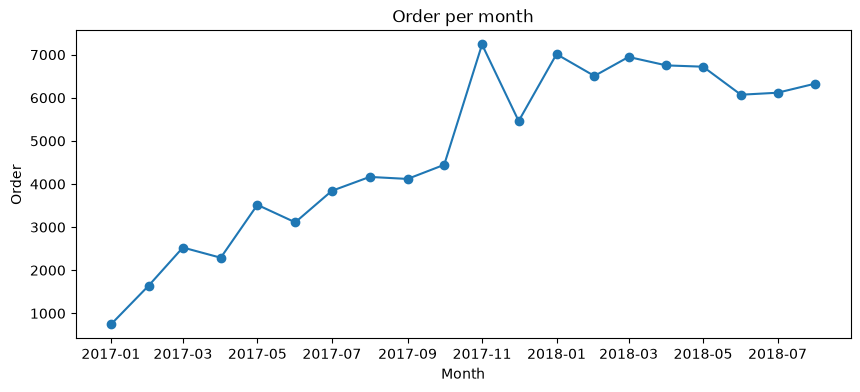

In [47]:
df = monthly.DataFrame()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["purchase_month"], df["orders"], marker="o")
ax.set_title("Order per month")
ax.set_xlabel("Month")
ax.set_ylabel("Order")
fig.savefig("../images/01_revenue_by_month.png", dpi=150, bbox_inches = "tight")
df.sort_values("orders", ascending=False).head(3)

**[Answer]:** Overall order and revenue gradually increase through 2017 to a peak about around November 2017 and followed by January 2018. The reason is possibly due to holiday season like black friday, as well as new years.

### Q2. How often are order late, and is it getting better ?

In [48]:
%%sql monthly_2 <<

SELECT 
    purchase_month,
    COUNT(*)                          AS orders,
    ROUND(100 * AVG(is_late::INT), 1) AS late_pct
FROM orders_enriched
GROUP BY purchase_month
ORDER BY purchase_month

Running query in 'duckdb:///../data/olist.duckdb'

In [49]:
monthly_2

purchase_month,orders,late_pct
2017-01-01,741,2.8
2017-02-01,1643,2.6
2017-03-01,2527,4.5
2017-04-01,2290,6.4
2017-05-01,3517,2.8
2017-06-01,3111,3.0
2017-07-01,3842,2.7
2017-08-01,4165,2.9
2017-09-01,4118,4.3
2017-10-01,4446,4.0


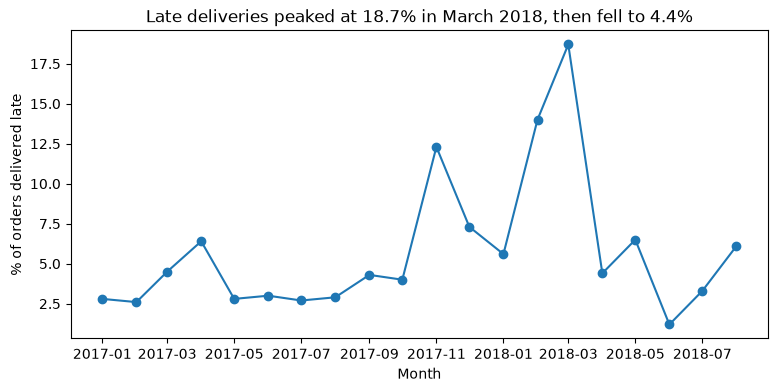

In [50]:
df = monthly_2.DataFrame()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df["purchase_month"], df["late_pct"], marker="o")
ax.set_xlabel("Month")
ax.set_ylabel("% of orders delivered late")
ax.set_title("Late deliveries peaked at 18.7% in March 2018, then fell to 4.4%")
fig.savefig("../images/02_late_rate_by_month.png", dpi=150, bbox_inches="tight")


**[Answer]:** About 6.7% of orders arrive late overall. The rate isn't steady: it peaked at 18.7% in March 2018, then fell to 4.4%. So delivery did get better in the second half of 2018, after a bad rate in early 2018.

### Q3. Do late orders get worse reivews ?

In [51]:
%%sql q3 <<

SELECT
    is_late,
    Count(*)        AS orders,
    ROUND(AVG(review_score), 2) AS avg_score,
    ROUND(100 * AVG(is_bad_review::INT), 1) AS bad_review_pct,
    ROUND(100 * AVG((review_score = 5)::INT), 1) AS five_star_pct
FROM orders_enriched
GROUP BY is_late
ORDER BY is_late
    


Running query in 'duckdb:///../data/olist.duckdb'

In [52]:
q3

is_late,orders,avg_score,bad_review_pct,five_star_pct
False,89182,4.29,9.2,62.3
True,6378,2.27,62.4,16.5


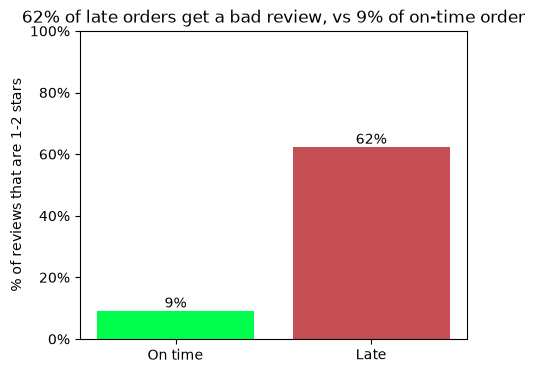

In [53]:
from matplotlib.ticker import PercentFormatter

df = q3.DataFrame().sort_values("is_late")
df["group"] = df["is_late"].map({False: "On time", True: "Late"})

fig, ax = plt.subplots(figsize = (5, 4))
ax.set_ylim(0, 100)
ax.bar(df["group"], df["bad_review_pct"], color=["#00FF4C", "#C44E52"])
ax.set_ylabel("% of reviews that are 1-2 stars")
ax.set_title("62% of late orders get a bad review, vs 9% of on-time order")
ax.yaxis.set_major_formatter(PercentFormatter())
for i, v in enumerate(df["bad_review_pct"]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")

fig.savefig("../images/03_bad_reviews_late_vs_on_time.png", dpi = 150, bbox_inches="tight")



**[Answer]:** Yes, much worse. 62.4% of late orders get a bad review (1-2 stars) vs 9.2% of on-time orders, which is about 7 times higher. The average score drops from 4.29 to 2.27, and only 16.5% of late orders get 5 stars, compared with 62.3% of on-time orders.

### Q4. Does how late the delivery is matter ?

In [54]:
%%sql
SELECT *
FROM orders_enriched
LIMIT 3

Running query in 'duckdb:///../data/olist.duckdb'

order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,days_late,is_late,review_score,n_items,revenue,freight,main_category,purchase_month,delivery_bucket,is_bad_review
e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,8,-8,False,4,1,29.99,8.72,housewares,2017-10-01,1. 8+ days early,False
53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,14,-6,False,4,1,118.7,22.76,perfumery,2018-07-01,2. 1-7 days early,False
47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,9,-18,False,5,1,159.9,19.22,auto,2018-08-01,1. 8+ days early,False


In [55]:
%%sql q4 <<
SELECT 
delivery_bucket,
COUNT(*)                                 AS orders,
ROUND(AVG(review_score), 2)              AS average_score,
ROUND(100 * AVG(is_bad_review::INT), 1 ) AS bad_review_pct
FROM orders_enriched
GROUP BY delivery_bucket
ORDER BY delivery_bucket


Running query in 'duckdb:///../data/olist.duckdb'

In [56]:
q4

delivery_bucket,orders,average_score,bad_review_pct
1. 8+ days early,70673,4.32,9.0
2. 1-7 days early,17229,4.2,10.2
3. On the estimated day,1280,4.03,12.4
4. 1-3 days late,1851,3.29,32.1
5. 4-7 days late,1748,2.1,67.7
6. 8-14 days late,1446,1.67,80.2
7. 15+ days late,1333,1.72,78.3


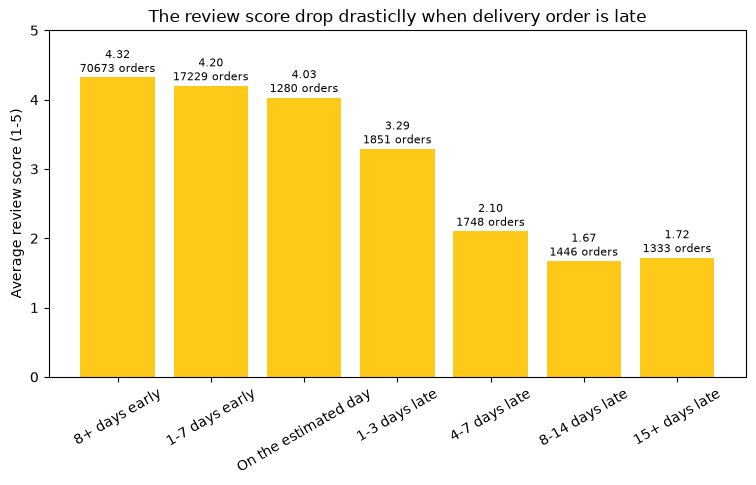

In [57]:
df = q4.DataFrame()
df["label"] = df["delivery_bucket"].str.replace(r"^\d+\.\s*", "", regex=True)
fig, ax = plt.subplots(figsize=(9,4.5))
ax.bar(df["label"], df["average_score"], color="#FFC919")
ax.set_ylim(0,5)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("The review score drop drasticlly when delivery order is late")
ax.tick_params(axis="x", rotation=30)
for i, (s, n) in enumerate(zip(df["average_score"], df["orders"])):
    ax.text(i, s + 0.08, f"{s:.2f}\n{n} orders", ha="center", fontsize=8)

fig.savefig("../images/04_avg_review_score_vs_delivery_date_bucket.png", dpi=150, bbox_inches="tight")

**[Answer]:** Yes. Scores stay high while orders arrive early or on time (4.03 to 4.32), then drop as soon as an order is late: 3.29 at 1-3 days late, 2.10 at 4-7 days, and around 1.7 at 8+ days. Bad reviews jump from about 12% on the estimated day to 32% at just 1-3 days late, and to about 80% beyond a week. Even a small delay hurts, and after about a week almost every customer is unhappy.

### Q5. Where are orders late most often appear (which specific group of location)

In [58]:
%%sql

SELECT *
FROM orders_enriched
LIMIT 3

Running query in 'duckdb:///../data/olist.duckdb'

order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,days_late,is_late,review_score,n_items,revenue,freight,main_category,purchase_month,delivery_bucket,is_bad_review
e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,8,-8,False,4,1,29.99,8.72,housewares,2017-10-01,1. 8+ days early,False
53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,14,-6,False,4,1,118.7,22.76,perfumery,2018-07-01,2. 1-7 days early,False
47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,9,-18,False,5,1,159.9,19.22,auto,2018-08-01,1. 8+ days early,False


In [59]:
%%sql q5 <<
SELECT
    customer_state,
    COUNT(*)                           AS orders,
    ROUND( 100 * AVG(is_late::INT), 1) AS late_percentage,
    MEDIAN(delivery_days)              AS medium_delivery_days
FROM orders_enriched
GROUP BY customer_state
HAVING COUNT(*) >= 500
ORDER BY late_percentage DESC

Running query in 'duckdb:///../data/olist.duckdb'

[Answer]: Late delivery are concentrated in Northeast and North, led by MA (17.2%), CE(13.7%), which is pretty far from most seller since most order concentrated in Sao Paulo (SP). The excepton is Rio e Janeiro (RJ): althought it's close to Sao Paulo, and have second highest selling volume, 12% of its orders are late, nearly triple the rate in SP (4.4%). Since dlivery times in RJ are not too long (12 days), the problem might be the delivery estimates are too optimistic rather than distance.

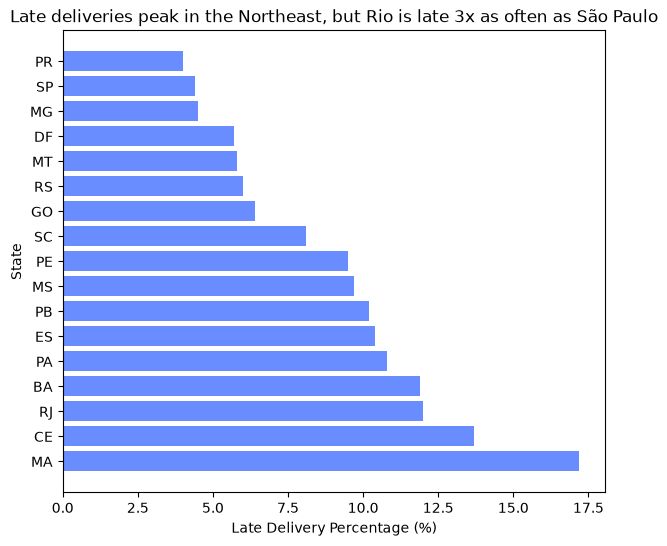

In [60]:
df = q5.DataFrame()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(df["customer_state"],df["late_percentage"], color="#698CFF")
ax.set_ylabel("State")
ax.set_xlabel("Late Delivery Percentage (%)")
ax.set_title("Late deliveries peak in the Northeast, but Rio is late 3x as often as São Paulo")
fig.savefig("../images/05.states_vs_late_delivery_percentage.png", dpi=150, bbox_inches="tight")

### Q6. Which categories get the worst reviews, and it latness the reason

In [61]:
%%sql

select *
from orders_enriched
limit 2

Running query in 'duckdb:///../data/olist.duckdb'

order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,days_late,is_late,review_score,n_items,revenue,freight,main_category,purchase_month,delivery_bucket,is_bad_review
e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,8,-8,False,4,1,29.99,8.72,housewares,2017-10-01,1. 8+ days early,False
53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,14,-6,False,4,1,118.7,22.76,perfumery,2018-07-01,2. 1-7 days early,False


In [62]:
%%sql q6 <<

SELECT 
    main_category,
    COUNT(*)                           AS orders,
    ROUND(AVG(review_score), 2)        AS average_review_score,
    ROUND( 100 * AVG(is_late::INT), 1) AS late_percentage
FROM orders_enriched
GROUP BY main_category
HAVING COUNT(*) >= 300
AND main_category <> 'Unknown'
ORDER BY average_review_score ASC
LIMIT 20

Running query in 'duckdb:///../data/olist.duckdb'

In [63]:
q6

main_category,orders,average_review_score,late_percentage
office_furniture,1236,3.66,8.0
audio,339,3.84,11.8
home_confort,352,3.93,9.9
bed_bath_table,9106,4.01,7.3
home_construction,468,4.03,6.2
telephony,4042,4.06,7.1
furniture_living_room,403,4.08,7.2
furniture_decor,6097,4.08,7.2
computers_accessories,6469,4.08,6.3
watches_gifts,5431,4.12,7.3


In [64]:
%%sql

SELECT
    ROUND(AVG(review_score), 2)       AS overall_avg_score,
    ROUND(100 * AVG(is_late::INT), 1) AS overall_late_pct
FROM orders_enriched
WHERE main_category <> 'Unknown'

Running query in 'duckdb:///../data/olist.duckdb'

overall_avg_score,overall_late_pct
4.16,6.7


In [65]:
%%sql

SELECT
    main_category,
    COUNT(*)                    AS on_time_orders,
    ROUND(AVG(review_score), 2) AS on_time_avg_score
FROM orders_enriched
WHERE main_category IN ('office_furniture', 'audio', 'home_confort')
  AND NOT is_late
GROUP BY main_category
ORDER BY on_time_avg_score


Running query in 'duckdb:///../data/olist.duckdb'

main_category,on_time_orders,on_time_avg_score
office_furniture,1137,3.77
home_confort,317,4.11
audio,299,4.12


[Answer]: The average late delivery is around 6.7%. Audio (3.84, 11.8% late) and home comfort (3.93, 9.9% late) are late more often than average, so delivery contriubute to their low scores, but for office furniture has the lowest scores, with a late rate close to average (8%), and even it's on-time delivery only score 3.77. This problem might likely due to the product quality, damage in trainsit, or description doesn't match

### Q7. Do late deliveries cost repeat customers

In [66]:
%%sql

select *
from orders_enriched
limit 3

Running query in 'duckdb:///../data/olist.duckdb'

order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,days_late,is_late,review_score,n_items,revenue,freight,main_category,purchase_month,delivery_bucket,is_bad_review
e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,8,-8,False,4,1,29.99,8.72,housewares,2017-10-01,1. 8+ days early,False
53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,14,-6,False,4,1,118.7,22.76,perfumery,2018-07-01,2. 1-7 days early,False
47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,9,-18,False,5,1,159.9,19.22,auto,2018-08-01,1. 8+ days early,False


In [67]:
%%sql

SELECT
    customer_unique_id,
    order_purchase_timestamp,
    is_late,
    ROW_NUMBER() OVER (
        PARTITION BY customer_unique_id
        ORDER BY order_purchase_timestamp, order_id
    ) AS order_number,
    COUNT(*) OVER (
        PARTITION BY customer_unique_id
    ) AS total_orders
FROM orders_enriched
ORDER BY total_orders DESC, customer_unique_id, order_number
LIMIT 10


Running query in 'duckdb:///../data/olist.duckdb'

customer_unique_id,order_purchase_timestamp,is_late,order_number,total_orders
8d50f5eadf50201ccdcedfb9e2ac8455,2017-06-18 22:56:48,False,1,15
8d50f5eadf50201ccdcedfb9e2ac8455,2017-07-18 23:10:58,False,2,15
8d50f5eadf50201ccdcedfb9e2ac8455,2017-07-24 22:11:50,False,3,15
8d50f5eadf50201ccdcedfb9e2ac8455,2017-08-05 08:59:43,False,4,15
8d50f5eadf50201ccdcedfb9e2ac8455,2017-09-05 22:14:52,False,5,15
8d50f5eadf50201ccdcedfb9e2ac8455,2017-10-18 23:25:04,False,6,15
8d50f5eadf50201ccdcedfb9e2ac8455,2017-10-29 16:58:02,False,7,15
8d50f5eadf50201ccdcedfb9e2ac8455,2017-11-22 20:01:53,False,8,15
8d50f5eadf50201ccdcedfb9e2ac8455,2018-05-21 22:44:31,False,9,15
8d50f5eadf50201ccdcedfb9e2ac8455,2018-05-22 23:08:55,False,10,15


In [68]:
%%sql q7 <<

WITH first_orders AS (
    SELECT
        customer_unique_id,
        is_late AS first_order_late,
        COUNT(*) OVER (PARTITION BY customer_unique_id) AS total_orders
    FROM orders_enriched
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY customer_unique_id
        ORDER BY order_purchase_timestamp, order_id
    ) = 1
)
SELECT
    first_order_late,
    COUNT(*)                                     AS customers,
    COUNT(*) FILTER (WHERE total_orders > 1)     AS came_back,
    ROUND(100 * AVG((total_orders > 1)::INT), 2) AS repeat_pct
FROM first_orders
GROUP BY first_order_late
ORDER BY first_order_late


Running query in 'duckdb:///../data/olist.duckdb'

In [69]:
%%sql

WITH first_orders AS (
    SELECT
        customer_unique_id,
        COUNT(*) OVER (PARTITION BY customer_unique_id) AS total_orders
    FROM orders_enriched
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY customer_unique_id
        ORDER BY order_purchase_timestamp, order_id
    ) = 1
)
SELECT
    COUNT(*)                                     AS customers,
    ROUND(100 * AVG((total_orders > 1)::INT), 2) AS repeat_pct
FROM first_orders


Running query in 'duckdb:///../data/olist.duckdb'

customers,repeat_pct
92496,2.98


In [70]:
q7

first_order_late,customers,came_back,repeat_pct
False,86288,2596,3.01
True,6208,156,2.51


[Answer]: Overall, we can see that only 2.98% of customers placed a second order, so repeat customer is rare on Olist. When the first order arrived late, 2.51% came back, compared with 3.01% when it arrived on time, about 17% fewer returning customers. The difference is small and based on only 156 returning customers, so it is a signal rather than proof. Late delivery clearly hurts reviews based on Q3, but its effect on repeat purchases is much weaker. The bigger issue is that almost no one comes back at all, whatever their delivery experience.

### Q8. Is the effect of late delivery real, or could something else explain it?

#### Q8a. Is the difference statistically significant?

In [71]:
%%sql q8a <<

SELECT
    COUNT(*) FILTER (WHERE is_late AND is_bad_review)     AS bad_late,
    COUNT(*) FILTER (WHERE is_late)                       AS n_late,
    COUNT(*) FILTER (WHERE NOT is_late AND is_bad_review) AS bad_on_time,
    COUNT(*) FILTER (WHERE NOT is_late)                   AS n_on_time
FROM orders_enriched

Running query in 'duckdb:///../data/olist.duckdb'

In [72]:
q8a

bad_late,n_late,bad_on_time,n_on_time
3981,6378,8247,89182


In [73]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

z = q8a.DataFrame().iloc[0]
stat, p = proportions_ztest(
    count=[z.bad_late, z.bad_on_time], 
    nobs=[z.n_late, z.n_on_time])
low, high = confint_proportions_2indep(z.bad_late, z.n_late, z.bad_on_time, z.n_on_time)

p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

print(f"z = {stat:.1f}, {p_text}")
print(f"Late orders have {low*100:.1f} to {high*100:.1f} percentage points more bad reviews (95% CI)")

z = 122.8, p < 0.001
Late orders have 52.0 to 54.4 percentage points more bad reviews (95% CI)


In [74]:
r = q7.DataFrame().set_index("first_order_late")

came_back = [r.loc[True, "came_back"], r.loc[False, "came_back"]]   
customers = [r.loc[True, "customers"], r.loc[False, "customers"]]

stat, p = proportions_ztest(
    count=came_back, 
    nobs=customers)
low, high = confint_proportions_2indep(came_back[0], customers[0], came_back[1], customers[1])

p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
print(f"z = {stat:.2f}, {p_text}")
print(f"Difference in repeat rate (late minus on time): {low*100:.2f} to {high*100:.2f} percentage points (95% CI)")

z = -2.22, p = 0.026
Difference in repeat rate (late minus on time): -0.87 to -0.06 percentage points (95% CI)


**[Answer]:** The difference in bad reviews is statistically significant (z = 122.8, p < 0.001). Late orders have 52.0 to 54.4 percentage points more bad reviews than on-time orders (95% CI), so the gap is far too large to be chance.

Running the same test on repeat customers (Q7) gives z = -2.22, p = 0.026. That difference is also significant, but much weaker: a late first order lowers the repeat rate by between 0.06 and 0.87 percentage points (95% CI). Late delivery strongly damages reviews, and only slightly reduces the chance a customer returns.

#### Q8b. Does the gap hold within each category?

In [75]:
%%sql q8b <<

SELECT
    main_category,
    COUNT(*) FILTER (WHERE NOT is_late)                    AS on_time_orders,
    COUNT(*) FILTER (WHERE is_late)                        AS late_orders,
    ROUND(AVG(review_score) FILTER (WHERE NOT is_late), 2) AS avg_score_on_time,
    ROUND(AVG(review_score) FILTER (WHERE is_late), 2)     AS avg_score_late,
    ROUND(
        AVG(review_score) FILTER (WHERE NOT is_late)
      - AVG(review_score) FILTER (WHERE is_late), 2
    )                                                      AS gap
FROM orders_enriched
WHERE main_category <> 'Unknown'
GROUP BY main_category
HAVING COUNT(*) FILTER (WHERE is_late) >= 100
ORDER BY gap DESC

Running query in 'duckdb:///../data/olist.duckdb'

In [76]:
q8b

main_category,on_time_orders,late_orders,avg_score_on_time,avg_score_late,gap
toys,3505,232,4.38,2.13,2.25
baby,2507,218,4.3,2.07,2.23
sports_leisure,6944,486,4.38,2.17,2.21
fashion_bags_accessories,1693,100,4.37,2.19,2.18
stationery,2084,146,4.45,2.32,2.13
perfumery,2833,200,4.4,2.29,2.11
cool_stuff,3289,204,4.35,2.25,2.1
watches_gifts,5036,395,4.27,2.2,2.07
housewares,5337,300,4.32,2.26,2.06
health_beauty,7900,631,4.39,2.34,2.04


**[Answer]:** The gap is so consistent across very different products, the product mix cannot explain it, late delivery itself is what drives the lower scores.

In [77]:
%%sql

COPY (SELECT * FROM orders_enriched) to '../data/processed/tableau_orders.csv' (header, delimiter ',')


Running query in 'duckdb:///../data/olist.duckdb'

Count


In [78]:
%sql --close duckdb:///../data/olist.duckdb